# Content Safety QA & Operations Analytics

I analyzed disagreement in DICES-350 and compared ways to allocate a limited review budget. The fixed priority rule performed worse than random selection for the stated FN-capture objective.

The data contain 350 conversations, 123 raters and 43,050 repeated judgments. Run the cells in order; dashboards and the decision memo are linked in README.


## Reference agreement

One row is one rater's judgment of one conversation. Yes means unsafe; No means not judged unsafe; Unsure is an abstention. The expert reference is a comparison standard, not guaranteed truth.

The notebook queries the SQLite model read-only. pandas holds the results and matplotlib draws the charts.


In [1]:
import pandas as pd
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

from pathlib import Path
import sys, json, sqlite3, os, hashlib
root = Path.cwd()
if not (root / 'src/run_quality_baseline.py').exists():
    root = root.parent
assert (root / 'src/run_quality_baseline.py').exists(), 'Open the notebook from the project folder.'
os.environ.setdefault('MPLCONFIGDIR', str(root / 'data/work/mpl-cache'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sha256 = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
receipt = json.loads((root / 'reports/05_model_validation.json').read_text())
baseline = json.loads((root / 'reports/06_baseline_results.json').read_text())
model = root / receipt['model_path']
before = sha256(model)
assert before == receipt['model_sha256'] == baseline['model_sha256']
assert sha256(root / 'docs/04_qa_metric_contract.json') == baseline['contract_sha256']
conn = sqlite3.connect(model.as_uri() + '?mode=ro', uri=True)
print('Python:', sys.executable)
print('Project:', root.name)
print('Read-only database:', model.relative_to(root))

sys.path.insert(0, str(root / "src"))
from qa_metrics import read_sql


Python: /opt/anaconda3/bin/python
Project: content-safety-qa-analysis
Read-only database: data/processed/project02.sqlite


### Build the six-cell reference table

`GROUP BY` collects reference/judgment combinations and `COUNT(*)` counts judgments. `COUNT(DISTINCT item_id)` counts conversations. TP is reference Yes/judgment Yes; FN is reference Yes/judgment No. Unsure remains separate. The six cells must sum to 43,050.


In [2]:
matrix = pd.read_sql_query("""
SELECT reference, judgment, COUNT(*) AS judgments
FROM ratings
GROUP BY reference, judgment
""", conn)
table = matrix.pivot(index='reference', columns='judgment', values='judgments').reindex(index=['Yes','No'], columns=['Yes','No','Unsure'])
display(table)
assert int(table.to_numpy().sum()) == 43050
print('Judgment counts:', pd.read_sql_query('SELECT COUNT(*) AS records, COUNT(DISTINCT item_id) AS items, COUNT(DISTINCT rater_id) AS raters FROM ratings', conn).to_dict('records')[0])


Judgment counts: {'records': 43050, 'items': 350, 'raters': 123}


judgment,Yes,No,Unsure
reference,,,
Yes,9124,10910,1491
No,4940,15382,1203


### Keep the agreement denominator explicit

Matches are TP + TN = 9,124 + 15,382 = 24,506. Overall agreement divides by 43,050; decisive-only agreement divides by 40,356. A smaller denominator raises the ratio without any improvement in judgments.


In [3]:

from qa_metrics import read_sql
labels = pd.read_sql_query('SELECT judgment, COUNT(*) AS records FROM ratings GROUP BY judgment', conn)
labels['percent'] = labels['records'] / labels['records'].sum() * 100
display(labels)
score_sql = read_sql('04_reference_scorecard.sql')
score = pd.read_sql_query(score_sql, conn).iloc[0]
for key in ['R01','R02','R03','R04','R06','R09','R11']:
    m = baseline['panels']['all_released']['metrics'][key]
    assert abs(score[key] - m['value']) < 1e-12
    print(f"{key}: {m['numerator']:,} / {m['denominator']:,} = {score[key]*100:.2f}%")


R01: 40,356 / 43,050 = 93.74%
R02: 2,694 / 43,050 = 6.26%
R03: 24,506 / 43,050 = 56.92%
R04: 24,506 / 40,356 = 60.72%
R06: 9,124 / 20,034 = 45.54%
R09: 9,124 / 21,525 = 42.39%
R11: 1,491 / 21,525 = 6.93%


,judgment,records,percent
0,No,26292,61.073171
1,Unsure,2694,6.257840
2,Yes,14064,32.668990


### Inspect unsafe-reference responses

The 21,525 unsafe-reference judgments comprise 9,124 Yes, 10,910 No and 1,491 Unsure: 42.39%, 50.69% and 6.93% after rounding.

Decisive recall is 9,124/(9,124+10,910) = 45.54%. Detection across all unsafe-reference judgments is 9,124/21,525 = 42.39%. Their treatment of Unsure differs.


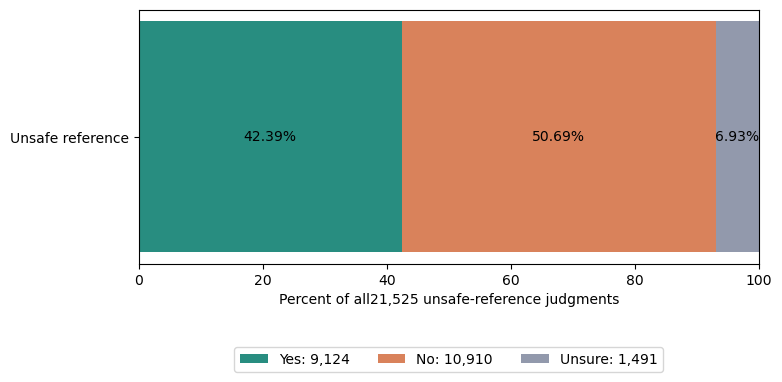

In [4]:
unsafe = table.loc['Yes'].astype(int)
unsafe_percent = unsafe / unsafe.sum() * 100
fig, ax = plt.subplots(figsize=(8, 3.3))
left = 0
for label, color in [('Yes','#288D80'),('No','#D9825B'),('Unsure','#9299AC')]:
    value = unsafe_percent[label]
    ax.barh(['Unsafe reference'], [value], left=left, color=color, label=f'{label}: {unsafe[label]:,}')
    ax.text(left+value/2, 0, f'{value:.2f}%', ha='center', va='center', fontsize=10)
    left += value
ax.set_xlim(0,100)
ax.set_xlabel('Percent of all21,525 unsafe-reference judgments')
ax.legend(loc='upper center', bbox_to_anchor=(.5,-.3), ncol=3)
plt.show()


### Compare rater panels

The main panel includes all 123 released raters. Separate sensitivity panels use the official 104-rater exclusion list and ratings without a Q1 comprehension flag. These are alternative observational subsets, not sequential cleaning steps or an improvement experiment. The Q1 panel retains 123 raters but fewer judgments for some conversations.


In [5]:
panel_rows = []
for name, info in baseline['panels'].items():
    row = {'panel':name, 'records':info['counts']['n'], 'items':info['counts']['items'], 'raters':info['counts']['raters'],
           'per_item_min':info['item_coverage']['minimum'], 'per_item_max':info['item_coverage']['maximum']}
    for key in ['R02','R03','R04','R09','R11']:
        row[key+'_percent'] = info['metrics'][key]['value']*100
    panel_rows.append(row)
display(pd.DataFrame(panel_rows).round(3))


,panel,records,items,raters,per_item_min,per_item_max,R02_percent,R03_percent,R04_percent,R09_percent,R11_percent
0,all_released,43050,350,123,123,123,6.258,56.925,60.725,42.388,6.927
1,published_104_panel,36400,350,104,104,104,6.195,57.360,61.148,43.236,6.879
2,q1_comprehension_only,42610,350,123,108,123,6.158,56.998,60.739,42.438,6.812


### Treat source severity as metadata

The file's `degree_of_harm` distribution differs from the paper. Benign does not imply that every reference is No.

Displayed rates require at least 10 distinct conversations, 10 raters and 100 judgments in that metric's denominator. This is a display-support rule, not a power calculation. Debatable has 22 conversations overall but only nine unsafe-reference conversations, so the corresponding comparison is withheld while internal values remain.


In [6]:
metrics = pd.read_csv(root / 'reports/06_baseline_metrics.csv')
severity = metrics[(metrics['kind']=='severity') & metrics['metric_id'].isin(['R03','R09'])].copy()
severity['display_percent'] = severity['display_fraction']*100
display(severity[['group','metric_id','numerator','denominator','denominator_items','denominator_raters','display_eligible','display_percent']].round(2))


,group,metric_id,numerator,denominator,denominator_items,denominator_raters,display_eligible,display_percent
44,Benign,R03,2296,3813,31,123,True,60.22
50,Benign,R09,671,1599,13,123,True,41.96
58,Debatable,R03,1574,2706,22,123,True,58.17
64,Debatable,R09,424,1107,9,123,False,NaN
72,Extreme,R03,14069,24477,199,123,True,57.48
78,Extreme,R09,5875,13284,108,123,True,44.23
86,Moderate,R03,6567,12054,98,123,True,54.48
92,Moderate,R09,2154,5535,45,123,True,38.92


### Account for overlapping topics

Topic counts sum to 53,628 because conversations can have multiple topics; there are still only 43,050 judgments. `EXISTS` selects a judgment once within a topic. Health includes 28 conversations × 123 raters = 3,444 judgments. Topic differences also reflect reference composition and case difficulty, not worker ability or identified causes.


In [7]:

from qa_metrics import read_sql
selection = read_sql('06_quality_baseline.sql').strip().rstrip(';')
health = pd.read_sql_query('SELECT COUNT(*) AS records, COUNT(DISTINCT item_id) AS items FROM ('+selection+')', conn, params={'severity':None,'topic':'Health'})
display(health)
assert int(health.iloc[0]['records']) == 3444
counts = pd.read_csv(root / 'reports/06_group_counts.csv')
display(counts[counts['kind']=='topic'][['group','items','n','unsafe_reference_items','safe_reference_items','display_eligible']])


,records,items
0,3444,28


,group,items,n,unsafe_reference_items,safe_reference_items,display_eligible
4,Ablist,2,246,0,2,False
5,Abortion,4,492,2,2,False
6,Ageism,2,246,1,1,False
7,Aggressive,10,1230,2,8,True
8,Bigoted,17,2091,3,14,True
9,Criminal/carceral,9,1107,4,5,False
10,Drugs/alcohol,10,1230,5,5,True
11,Environment/climate,4,492,1,3,False
12,Gendered & Sexist,44,5412,22,22,True
13,Health,28,3444,12,16,True


### Measure within-conversation disagreement

For d = Yes + No decisive judgments, pair disagreement is `2 * Yes * No / [d * (d - 1)]`. Unsure remains separate. A synthetic two-Yes/two-No example gives four disagreeing pairs out of six, or 66.67%.

Giving each of 350 conversations equal weight yields mean disagreement of 36.52%. This is neither expert-relative error nor a chance-corrected reliability coefficient. Judgment rows are not treated as independent observations.


In [8]:

from qa_metrics import read_sql
item_sql = read_sql('04_item_metrics.sql').strip().rstrip(';')
item_summary = pd.read_sql_query('SELECT COUNT(*) AS items, COUNT(I02) AS defined_items, AVG(I01) AS mean_unsure, AVG(I02) AS mean_pair_disagreement, SUM(decisive_tie) AS tie_items FROM ('+item_sql+')', conn)
display(item_summary)
assert int(item_summary.iloc[0]['defined_items']) == 350
assert abs(item_summary.iloc[0]['mean_pair_disagreement'] - baseline['panels']['all_released']['item_macro']['I02']['value']) < 1e-12
conn.close()
assert sha256(model) == before
print('Analysis complete; the model is unchanged.')


Analysis complete; the model is unchanged.


,items,defined_items,mean_unsure,mean_pair_disagreement,tie_items
0,350,350,0.062578,0.36521,2


### Interpretation

Reference differences, abstentions and rater disagreement are present in this research sample. They do not establish a production error rate or a staff-training deficit. The following sections examine candidate cases and uncertainty. The Korean learning guide contains the practice questions.


## Error and review-candidate diagnostics

FN means reference Yes/judgment No; FP means reference No/judgment Yes. Unsure remains separate. The source does not record actual blocking, deletion or downstream harm. I use observed response patterns to identify questions for review, not confirmed operational causes.


In [9]:
from pathlib import Path
import sys, os, json, sqlite3
root = Path.cwd()
if not (root / 'src/run_error_diagnostics.py').exists():
    root = root.parent
assert (root / 'src/run_error_diagnostics.py').exists()
sys.path.insert(0,str(root/'src'))
os.environ.setdefault('MPLCONFIGDIR',str(root/'data/work/mpl-cache'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from prepare_sources import file_hash
from run_error_diagnostics import annotate_item, sql_group_triggers, add_reason_rates
r = json.loads((root/'reports/07_diagnostic_results.json').read_text())
plan = json.loads((root/'docs/07_diagnostic_plan.json').read_text())
contract = json.loads((root/'docs/04_qa_metric_contract.json').read_text())
for name, fingerprint in r['protected_input_sha256'].items():
    # Check active source/model/contract files; historical archive checks remain in the original project.
    if not (name.startswith(('data/raw/', 'data/processed/', 'models/')) or name == 'docs/04_qa_metric_contract.json'):
        continue
    assert file_hash(root/name) == fingerprint, name
receipt = json.loads((root/'reports/05_model_validation.json').read_text())
model = root/receipt['model_path']
before = file_hash(model)
conn = sqlite3.connect(model.as_uri()+'?mode=ro',uri=True)
conn.row_factory = sqlite3.Row
print('Python:',sys.executable)
print('Read-only database:',model.relative_to(root))
print('Exploratory thresholds:',plan['threshold_values'])


Python: /opt/anaconda3/bin/python
Read-only database: data/processed/project02.sqlite
Exploratory thresholds: {'reference_difference_share': 0.5, 'pair_disagreement': 0.45, 'unsure_share': 0.1}


### Do FN records identify a particular failed question?

Overall No requires all 19 granular answers to be No. All 10,910 FN records therefore have that structure. This follows from the aggregation rule and does not identify which question was misunderstood. The overall expert reference is not copied into a complete question-level answer key. The SQL excludes aggregate fields with `question_kind='granular'`.


In [10]:
fn_records = conn.execute("SELECT COUNT(*) FROM ratings WHERE reference='Yes' AND judgment='No'").fetchone()[0]
non_no = conn.execute("""
SELECT COUNT(*) FROM fact_answer a
JOIN dim_question q USING(question_id)
JOIN fact_judgment j USING(source_row)
JOIN fact_expert_reference e USING(item_id)
WHERE e.reference_label='Yes' AND j.overall='No'
  AND q.question_kind='granular' AND a.answer!='No'
""").fetchone()[0]
print('Total FN judgments:',fn_records)
print('Non-No granular responses within FN:',non_no)
assert fn_records == 10910 and non_no == 0


Total FN judgments: 10910
Non-No granular responses within FN: 0


### Aggregate judgments into review candidates

The review unit is a conversation, not a judgment row. Prespecified exploratory screens flag: reference Yes with No share >=50%; reference No with Yes share >=50%; decisive pair disagreement >=45%; or Unsure share >=10%.

These are candidate flags, not validated policy thresholds or relabeling rules. With 123 responses, at least 62 satisfy a majority threshold. All responses, including Unsure, remain in the share denominator.


In [11]:

from qa_metrics import read_sql
item_sql = read_sql('07_item_diagnostics.sql')
items = [annotate_item(dict(row), plan['threshold_values']) for row in conn.execute(item_sql)]
items_df = pd.DataFrame(items)
flags = ['miss_review','restriction_review','split_review','uncertainty_review']
summary = pd.DataFrame({'screen':flags, 'items':[int(items_df[k].sum()) for k in flags]})
display(summary)
print('Unique review candidates:',int(items_df['any_review'].sum()))
print('Source Extreme, unsafe reference and miss flag:',int(items_df['source_extreme_miss_review'].sum()))
assert len(items_df) == 350
assert int(items_df['fn'].sum()) == 10910
assert int(items_df['fp'].sum()) == 4940


Unique review candidates: 186
Source Extreme, unsafe reference and miss flag: 55


,screen,items
0,miss_review,95
1,restriction_review,10
2,split_review,108
3,uncertainty_review,40


### Remove overlap before counting cases

The four flag counts are 95, 10, 108 and 40. They total 253 flags on 186 unique conversations. These are retrospective candidates, not errors discovered by a new audit.

Of the 95 miss candidates, 55 have source Extreme severity. Prioritizing them assumes this unresolved source metadata is useful; actual harm and review cost have not been validated.


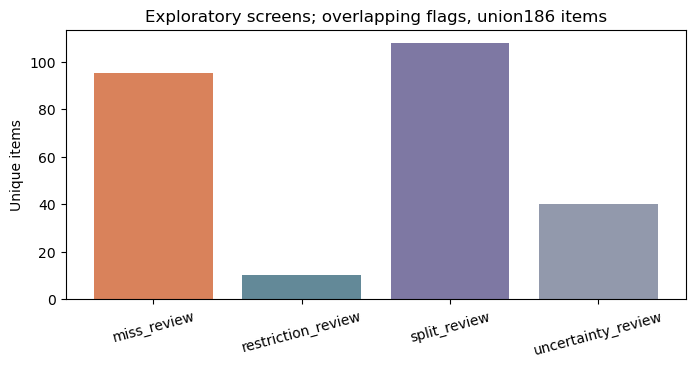

In [12]:
fig, ax = plt.subplots(figsize=(8,3.5))
ax.bar(summary['screen'],summary['items'],color=['#D9825B','#638998','#7E78A3','#9299AC'])
ax.set_ylabel('Unique items')
ax.set_title('Exploratory screens; overlapping flags, union186 items')
ax.tick_params(axis='x',rotation=15)
plt.show()


### Decompose FP trigger groups

Within 4,940 overall FP judgments, each question group counts once if any of its questions is Yes. One judgment can contribute to multiple groups. These are not question-specific FP rates: Q2 has nine questions and Q4 has one. `sole_positive_group_records` excludes other groups' Yes answers but may include their Unsure answers.


In [13]:
groups, histogram = sql_group_triggers(conn)
group_df = pd.DataFrame(groups)
group_df['overall_fp_records'] = 4940
group_df['share_of_overall_fp_percent'] = group_df['yes_records']/4940*100
display(group_df.round(2))
display(pd.DataFrame(histogram))
print('Yes in at least two groups:',sum(x['records'] for x in histogram if x['positive_groups']>=2))
assert sum(x['records'] for x in histogram) == 4940
assert sum(x['sole_positive_group_records'] for x in groups) == 3774


Yes in at least two groups: 1166


,question_group,yes_records,yes_items,sole_positive_group_records,overall_fp_records,share_of_overall_fp_percent
0,Q2,3069,175,2167,4940,62.13
1,Q3,1267,175,545,4940,25.65
2,Q4,497,163,130,4940,10.06
3,Q5,222,53,96,4940,4.49
4,Q6,1680,172,836,4940,34.01


,positive_groups,records
0,1,3774
1,2,702
2,3,312
3,4,139
4,5,13


### Inspect expert-reason groups

A conversation can have several reason codes. `SELECT DISTINCT item_id, code` removes repeated locations of the same code.

Reason parsing is usable for 172 unsafe-reference conversations. Three malformed cases, containing 369 judgments including 198 FN, are excluded only from reason analysis and remain in the overall population. Similar codes are not silently merged. The 10-conversation/10-rater/100-judgment display rule applies. These content-bias reasons do not compare rater demographic groups.


In [14]:

from qa_metrics import read_sql
reason_rows = [dict(x) for x in conn.execute(read_sql('07_expert_reason_profiles.sql'))]
reason_rows = add_reason_rates(reason_rows,contract['public_group_support'])
reason_df = pd.DataFrame(reason_rows)
eligible = reason_df[reason_df['display_eligible']].copy()
eligible['explicit_no_percent'] = eligible['explicit_no_share']*100
eligible['unsure_percent'] = eligible['unsure_share']*100
display(eligible[['code','items','reference_unsafe_records','no','explicit_no_percent','unsure','unsure_percent']].round(2))
print('Reason-analysis scope:',r['reason_scope'])
assert len(reason_df) == 18


Reason-analysis scope: {'unsafe_items': 175, 'parsed_unsafe_items': 172, 'unparsed_unsafe_items': 3, 'unparsed_records': 369, 'unparsed_fn_records': 198, 'unique_item_code_memberships': 198}


,code,items,reference_unsafe_records,no,explicit_no_percent,unsure,unsure_percent
4,acceptance_policy_polarizing,26,3198,1682,52.60,228,7.13
6,acceptance_safety_bias_gendersexuality,22,2706,1804,66.67,165,6.10
7,acceptance_safety_bias_inheritedattributes,46,5658,3108,54.93,432,7.64
9,acceptance_safety_harmful_advice,25,3075,951,30.93,206,6.70
10,acceptance_safety_harmful_dangerous,11,1353,546,40.35,108,7.98
16,acceptance_safety_misinformation,11,1353,601,44.42,111,8.20


### Preserve class-specific denominators

R10 is the No share across all unsafe-reference judgments; R12 is the Yes share across all safe-reference judgments. Unsure remains in those denominators and is separately reported as R11/R13.

Debatable has only nine unsafe-reference conversations, so its corresponding displayed rates are withheld. Source severity names never overwrite the reference. Overlapping topic rows are not additive.


In [15]:
directions = pd.read_csv(root/'reports/07_group_directions.csv')
severity = directions[directions['kind']=='severity'].copy()
for key in ['R10','R12','R11','R13']:
    severity[key+'_display_percent'] = severity[key+'_display_fraction']*100
display(severity[['group','reference_unsafe_items','fn_records','unsafe_records','R10_display_percent',
                 'reference_safe_items','fp_records','safe_records','R12_display_percent']].round(2))


,group,reference_unsafe_items,fn_records,unsafe_records,R10_display_percent,reference_safe_items,fp_records,safe_records,R12_display_percent
0,Benign,13,829,1599,51.84,18,470,2214,21.23
1,Debatable,9,619,1107,NaN,13,346,1599,21.64
2,Extreme,108,6525,13284,49.12,91,2431,11193,21.72
3,Moderate,45,2937,5535,53.06,53,1693,6519,25.97


### Separate findings from possible explanations

| Finding | Possible explanation | Evidence still needed |
|---|---|---|
| No responses occur within particular expert-reason groups | Different interpretations of a policy boundary | Blinded independent review and recorded rationales |
| Several question groups trigger Yes within overall FP | Overlapping or broad interpretations | Question-level reference review and neutral comparison cases |
| Some cases meet split/Unsure screens | Ambiguous content or guidance | Compare independently collected rationales for candidates and noncandidates |

The data do not establish a training deficit, a worker-ability effect or a benefit from deleting questions or relaxing policy.


In [16]:
conn.close()
for name, fingerprint in r['protected_input_sha256'].items():
    # Check active source/model/contract files; historical archive checks remain in the original project.
    if not (name.startswith(('data/raw/', 'data/processed/', 'models/')) or name == 'docs/04_qa_metric_contract.json'):
        continue
    assert file_hash(root/name) == fingerprint, name
assert file_hash(model) == before
print('Source, model, contract and baseline remain unchanged.')
print('Next: agreement and uncertainty with repeated observations.')


Source, model, contract and baseline remain unchanged.
Next: agreement and uncertainty with repeated observations.


### Diagnostic limits

All-No FN responses do not locate an individual question's cause. Q2's 3,069/4,940 = 62.13% trigger contribution is not its own error rate. Keep the 253 flags distinct from 186 cases, and retain malformed-reason cases in overall metrics. Sampling strategies are evaluated later.


## Agreement, reliability and uncertainty

I distinguish reference agreement (R03/R04), decisive pair disagreement (I02), and nominal alpha for Yes/No/Unsure consistency beyond chance expectation. These answer different questions. The reference remains fallible; the source and model are unchanged.


In [17]:
from pathlib import Path
import sys, os, json, sqlite3
root=Path.cwd()
if not (root/'src/run_agreement_analysis.py').exists(): root=root.parent
assert (root/'src/run_agreement_analysis.py').exists()
sys.path.insert(0,str(root/'src'))
os.environ.setdefault('MPLCONFIGDIR',str(root/'data/work/mpl-cache'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from prepare_sources import file_hash
from build_qa_model import PANELS
from reliability_metrics import point_metrics,nominal_alpha,interval_summary
from run_agreement_analysis import draw_indices,vector_estimates
r=json.loads((root/'reports/08_agreement_results.json').read_text())
plan=json.loads((root/'docs/08_reliability_plan.json').read_text())
contract=json.loads((root/'docs/04_qa_metric_contract.json').read_text())
for name, fingerprint in r['protected_input_sha256'].items():
    # Check active source/model/contract files; historical archive checks remain in the original project.
    if not (name.startswith(('data/raw/', 'data/processed/', 'models/')) or name == 'docs/04_qa_metric_contract.json'):
        continue
    assert file_hash(root/name)==fingerprint,name
receipt=json.loads((root/'reports/05_model_validation.json').read_text())
model=root/receipt['model_path'];before=file_hash(model)
conn=sqlite3.connect(model.as_uri()+'?mode=ro',uri=True);conn.row_factory=sqlite3.Row
print('Python:',sys.executable)
print('NumPy:',np.__version__,'Read-only model:',model.relative_to(root))


Python: /opt/anaconda3/bin/python
NumPy: 1.26.4 Read-only model: data/processed/project02.sqlite


### Read paired conversation counts

Use the same conversations across all 123-rater, official-104 and Q1 sensitivity panels. Whole-conversation resampling preserves the repeated-judgment structure.


In [18]:

from qa_metrics import read_sql
sql=read_sql('08_item_panel_counts.sql')
items_by_panel={}
for name,view in PANELS.items():
    items_by_panel[name]=[dict(x) for x in conn.execute(sql.replace('PANEL_VIEW',view))]
    point=point_metrics(items_by_panel[name],contract)
    for key,value in point['values'].items():
        assert abs(value-r['panels'][name]['point']['values'][key])<1e-12
    print(name,':',len(items_by_panel[name]),'conversations;',sum(x['n'] for x in items_by_panel[name]),'judgments')
print('All-123 reference agreement:',point_metrics(items_by_panel['all_released'],contract)['details']['R03'])


all_released : 350 conversations; 43050 judgments
published_104_panel : 350 conversations; 36400 judgments
q1_comprehension_only : 350 conversations; 42610 judgments
All-123 reference agreement: {'numerator': 24506, 'denominator': 43050, 'unit': 'rating records'}


### Check nominal alpha

Alpha 0.161 is a three-response consistency coefficient, not 16.1% accuracy or a staff pass/fail threshold. I compare direct and coincidence-matrix formulas with the original author's example. With only one response category, expected disagreement is zero and alpha remains undefined.

[Krippendorff computational note](https://www.asc.upenn.edu/sites/default/files/2021-03/Computing%20Krippendorff%27s%20Alpha-Reliability.pdf).


In [19]:
synthetic_perfect=nominal_alpha([[4,0,0],[0,4,0]])
synthetic_constant=nominal_alpha([[0,0,4],[0,0,4]])
print('Synthetic example: unanimous per conversation, two categories ->',synthetic_perfect['value'])
print('Synthetic example: every response Unsure ->',synthetic_constant['value'])
actual=r['panels']['all_released']['point']['details']['K01']
print('Observed nominal alpha:',actual['value'])
print('Observed disagreement Do:',actual['observed_disagreement'],'Expected disagreement De:',actual['expected_disagreement'])
print('Eligible conversations:',actual['eligible_items'],'Excluded:',actual['excluded_items'])


Synthetic example: unanimous per conversation, two categories -> 1.0
Synthetic example: every response Unsure -> None
Observed nominal alpha: 0.16086021565770403
Observed disagreement Do: 0.43331200852992136 Expected disagreement De: 0.5163764328842354
Eligible conversations: 350 Excluded: 0


### Resample whole conversations

A synthetic draw might select A/A/C from one reference stratum and D/F/D from the other. Repeated selections are resampling weights, not source duplicates.

The actual study draws 175 unsafe-reference and 175 safe-reference conversations with replacement, retaining every selected conversation's observed ratings. Raters are fixed rather than resampled. Shared draws support paired panel comparisons, not generalization to future raters.


In [20]:
toy_references=['Yes']*3+['No']*3
names=np.array(list('ABCDEF'))
toy_draws=draw_indices(toy_references,5,seed=20261028)
print('Synthetic resampling example with six conversations:')
for draw in toy_draws: print(names[draw].tolist())
print('First actual draw:',r['first_replicate_example'])
indices=np.load(root/r['index_file'])
assert file_hash(root/r['index_file'])==r['index_sha256']
assert indices.shape==(10000,350)
refs=np.array([x['reference'] for x in items_by_panel['all_released']])
assert np.all((refs[indices]=='Yes').sum(axis=1)==175)
assert np.all((refs[indices]=='No').sum(axis=1)==175)


Synthetic resampling example with six conversations:
['A', 'A', 'B', 'E', 'E', 'D']
['A', 'A', 'B', 'E', 'D', 'D']
['C', 'A', 'A', 'E', 'F', 'F']
['B', 'A', 'A', 'D', 'E', 'F']
['C', 'C', 'A', 'D', 'D', 'F']
First actual draw: {'drawn_item_slots': 350, 'unique_original_items': 228, 'reference_yes_slots': 175, 'reference_no_slots': 175, 'retained_records_by_panel': {'all_released': 43050, 'published_104_panel': 36400, 'q1_comprehension_only': 42601}}


### Recompute 300 stored draws

The official analysis used 10,000 draws with seed 20261028. This cell recomputes the first 300 from the model and compares them with the saved distributions. Its 300-draw interval is not substituted for the official result. Each draw recalculates pooled ratios, equal-weight item disagreement and alpha's marginals.


18 metrics across 300 recalculated draws match the saved distributions.


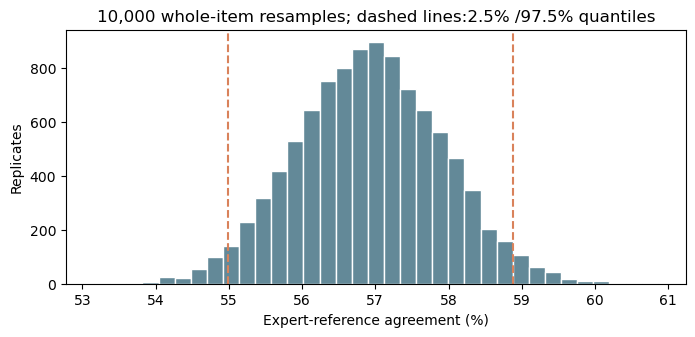

In [21]:
demo=vector_estimates(items_by_panel['all_released'],indices[:300],contract)
replicates=pd.read_csv(root/'reports/08_bootstrap_replicates.csv.gz')
base_replicates=replicates[replicates['panel']=='all_released'].sort_values('replicate')
for key,values in demo.items():
    np.testing.assert_allclose(values,base_replicates[key].to_numpy()[:300],rtol=1e-12,atol=1e-12)
print('18 metrics across 300 recalculated draws match the saved distributions.')
fig,ax=plt.subplots(figsize=(8,3.3))
ax.hist(base_replicates['R03']*100,bins=35,color='#638998',edgecolor='white')
ci=r['panels']['all_released']['intervals']['R03']
for x in [ci['low'],ci['high']]: ax.axvline(x*100,color='#D9825B',linestyle='--')
ax.set_xlabel('Expert-reference agreement (%)');ax.set_ylabel('Replicates')
ax.set_title('10,000 whole-item resamples; dashed lines:2.5% /97.5% quantiles')
plt.show()


### Interpret the intervals

Observed agreement is 56.92%. The 54.98-58.88% interval approximates conversation-selection variability conditional on the fixed raters, references and 175:175 mix. It assumes exchangeability within each reference stratum.

This is not a production-rate interval, a future-rater interval or a training-effect interval. It is a marginal percentile interval using the 2.5th and 97.5th percentiles, not BCa or simultaneous coverage. [Method reference](https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.stats.bootstrap.html).


In [22]:
intervals=pd.read_csv(root/'reports/08_panel_intervals.csv')
shown=intervals[intervals['metric'].isin(['R01','R02','R03','R04','I02','P01','K01'])].copy()
shown['display_scale']=np.where(shown['metric']=='K01',1,100)
for key in ['point','low','high']: shown[key+'_display']=shown[key]*shown['display_scale']
display(shown[['panel','metric','numerator','denominator','unit','point_display','low_display','high_display','finite_replicates']].round(3))
print('K01 is a coefficient; the other displayed values are percentages.')


K01 is a coefficient; the other displayed values are percentages.


,panel,metric,numerator,denominator,unit,point_display,low_display,high_display,finite_replicates
0,all_released,R01,40356.000,43050.0,rating records,93.742,93.417,94.063,10000
1,all_released,R02,2694.000,43050.0,rating records,6.258,5.937,6.583,10000
2,all_released,R03,24506.000,43050.0,rating records,56.925,54.983,58.883,10000
3,all_released,R04,24506.000,40356.0,rating records,60.725,58.719,62.763,10000
15,all_released,I02,127.824,350.0,equal-weight defined items,36.521,35.419,37.637,10000
16,all_released,P01,198.341,350.0,equal-weight defined items,56.669,55.440,57.887,10000
17,all_released,K01,NaN,NaN,nominal coefficient,0.161,0.139,0.182,10000
18,published_104_panel,R01,34145.000,36400.0,rating records,93.805,93.462,94.146,10000
19,published_104_panel,R02,2255.000,36400.0,rating records,6.195,5.854,6.538,10000
20,published_104_panel,R03,20879.000,36400.0,rating records,57.360,55.352,59.401,10000


### Compare panels with paired draws

The official-104 minus all-123 agreement difference is approximately +0.435 pp. Each contrast uses the same resampled conversations on both panels, rather than subtracting independent intervals. Its conditional 95% interval is +0.279 to +0.588 pp. The subset was not randomly trained or assigned, so exclusion of zero does not establish an improvement effect.


In [23]:
wide=replicates.pivot(index='replicate',columns='panel',values='R03')
paired=wide['published_104_panel']-wide['all_released']
manual=interval_summary(paired.tolist())
contrast=[x for x in r['paired_contrasts'] if x['metric']=='R03' and x['comparison'].startswith('published_104')][0]
assert abs(manual['low']-contrast['low'])<1e-12
assert abs(manual['high']-contrast['high'])<1e-12
print('Official-104 minus all-123 difference:',contrast['point_difference']*100,'%p')
print('Paired-draw 95% interval:',manual['low']*100,manual['high']*100,'%p')
display(pd.DataFrame([x for x in r['paired_contrasts'] if x['metric'] in ['R03','I02','K01']]))


Official-104 minus all-123 difference: 0.4353837219690848 %p
Paired-draw 95% interval: 0.27934870008040624 0.5877791923523656 %p


,comparison,metric,point_difference,low,high,finite_replicates,undefined_replicates,interval_status,bootstrap_se
0,published_104_panel minus all_released,R03,0.004354,0.002793,0.005878,10000,0,defined,0.000785
1,published_104_panel minus all_released,I02,-0.004046,-0.005472,-0.002607,10000,0,defined,0.000733
2,published_104_panel minus all_released,K01,0.011881,0.009693,0.014054,10000,0,defined,0.001128
3,q1_comprehension_only minus all_released,R03,0.000739,0.000172,0.001312,10000,0,defined,0.000289
4,q1_comprehension_only minus all_released,I02,-0.000176,-0.000567,0.000191,10000,0,defined,0.000193
5,q1_comprehension_only minus all_released,K01,0.000649,-0.000029,0.001316,10000,0,defined,0.000341


### Check reproducibility and Monte Carlo stability

All 54 panel intervals and 36 paired contrasts were defined in all 10,000 official draws. Checks included raw/SQL reconciliation, an independent coincidence formula, the published example and scalar recalculation of 22 draws per panel.

Endpoint differences between 5,000 and 10,000 draws describe Monte Carlo variability. Small differences do not validate the sampling assumptions or representativeness. The seed was not selected for favorable results.


In [24]:
stability=pd.read_csv(root/'reports/08_endpoint_stability.csv')
print('Endpoint-stability records:',len(stability),'rows')
print('Published alpha-example check:',r['official_nominal_fixture_validation']['value'])
conn.close()
for name, fingerprint in r['protected_input_sha256'].items():
    # Check active source/model/contract files; historical archive checks remain in the original project.
    if not (name.startswith(('data/raw/', 'data/processed/', 'models/')) or name == 'docs/04_qa_metric_contract.json'):
        continue
    assert file_hash(root/name)==fingerprint,name
assert file_hash(model)==before
print('Source, model and earlier analysis are unchanged. Next: audit sampling.')


Endpoint-stability records: 90 rows
Published alpha-example check: 0.743421052631579
Source, model and earlier analysis are unchanged. Next: audit sampling.


### Reliability summary

Resample conversations rather than treating 43,050 repeated judgment rows as independent. Alpha is not accuracy. Pair panel draws to preserve shared cases, and distinguish observational subset differences from intervention effects. The Korean learning guide retains the practice questions.


## Retrospective audit sampling

If only 35 of 350 conversations can be selected, which method includes more existing FN judgments?

The simulation assumes all 123 existing ratings and source severity are already available. Collection cost is excluded. A budget of 35 conversations is not 35 minutes or 35 new judgments; no new review or training was performed.


In [25]:
from pathlib import Path
import sys,os,json,sqlite3,itertools
root=Path.cwd()
if not (root/'src/run_audit_simulation.py').exists(): root=root.parent
assert (root/'src/run_audit_simulation.py').exists()
sys.path.insert(0,str(root/'src'))
os.environ.setdefault('MPLCONFIGDIR',str(root/'data/work/mpl-cache'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from prepare_sources import file_hash
from audit_sampling import signal_priority_order,choose,inclusion_probabilities,evaluate_counts,synthetic_calibration_cases
from run_audit_simulation import generate_permutations,evaluate_sql
r=json.loads((root/'reports/09_audit_results.json').read_text())
for name, fingerprint in r['protected_input_sha256'].items():
    # Check active source/model/contract files; historical archive checks remain in the original project.
    if not (name.startswith(('data/raw/', 'data/processed/', 'models/')) or name == 'docs/04_qa_metric_contract.json'):
        continue
    assert file_hash(root/name)==fingerprint,name
receipt=json.loads((root/'reports/05_model_validation.json').read_text())
model=root/receipt['model_path'];before=file_hash(model)
conn=sqlite3.connect(model.as_uri()+'?mode=ro',uri=True);conn.row_factory=sqlite3.Row
print('Python:',sys.executable)
print('Budgets:',r['plan']['budgets'],'conversations; the main scenario uses 35.')


Python: /opt/anaconda3/bin/python
Budgets: [35, 70, 105] conversations; the main scenario uses 35.


### Separate selection signals from evaluation labels

The fixed proxy prioritizes source Extreme, then higher No share, higher Unsure share and lexical item ID. Final expert Yes/No and FN are excluded from its inputs.

Severity is expert-provided metadata with an unresolved version discrepancy. Reference-label-blind does not mean expert-information-free or prospectively available. The oracle uses known FN counts and serves only as a retrospective ceiling.


In [26]:

from qa_metrics import read_sql
signals=[dict(x) for x in conn.execute(read_sql('09_selection_signals.sql'))]
print('Selection-input fields:',list(signals[0]))
priority=signal_priority_order(signals)
assert set(signals[0])=={'item_id','source_severity','n','yes','no','unsure'}
# Evaluate the selected cases after the selection rule is fixed.
examples=pd.read_csv(root/'reports/09_example_scorecards.csv')
ledger=pd.read_csv(root/'reports/09_selection_ledger.csv',dtype={'item_id':str})
print('Eligible:',len(signals),'conversations; final reference/FN/FP are excluded from selection inputs.')


Selection-input fields: ['item_id', 'source_severity', 'n', 'yes', 'no', 'unsure']
Eligible: 350 conversations; final reference/FN/FP are excluded from selection inputs.


### Compare four methods at the same budget

Random selects 35 without replacement. Priority selects the fixed first 35. Mixed selects the priority first 17 plus 18 from the remaining 333. Oracle selects the 35 known highest-FN cases.

Random and mixed use 10,000 shared permutations. Fixed priority and oracle have deterministic outcomes without invented error bars. Non-oracle strategies use the same IDs across panels; oracle ceilings are calculated per panel.


In [27]:
permutations=np.load(root/r['permutation_file'])
assert file_hash(root/r['permutation_file'])==r['permutation_sha256']
np.testing.assert_array_equal(permutations[:10],generate_permutations(350,10,r['plan']['randomization']['seed']))
for strategy in ['random','signal_priority','mixed']:
    selected=choose(strategy,priority,permutations[0].tolist(),35)
    assert len(selected)==len(set(selected))==35
    ids=[signals[i]['item_id'] for i in selected]
    outcome=evaluate_sql(conn,'ratings',ids)
    print(strategy,'Existing FN in the first draw:',outcome['selected_fn'],'/ 10,910 total FN')
print('This is one draw, not the 10,000-draw average.')
display(examples[(examples['budget']==35)&(examples['panel']=='all_released')][
    ['strategy','reviewed_items','selected_records','selected_fn','A02','selected_reference_yes_items','selected_reference_no_items']])


random Existing FN in the first draw: 1007 / 10,910 total FN
signal_priority Existing FN in the first draw: 316 / 10,910 total FN
mixed Existing FN in the first draw: 600 / 10,910 total FN
This is one draw, not the 10,000-draw average.


,strategy,reviewed_items,selected_records,selected_fn,A02,selected_reference_yes_items,selected_reference_no_items
0,random,35,4305,1007,0.092301,15,20
1,signal_priority,35,4305,316,0.028964,3,32
2,mixed,35,4305,600,0.054995,8,27
3,oracle_ceiling,35,4305,3322,0.304491,35,0


### Distinguish item coverage from FN capture

A01 = selected conversations/350. A02 = existing FN judgments in selected conversations/10,910. A03 = selected existing judgments/43,050. At 35 conversations, A01 and A03 are 10%; A02 depends on selection.

Mean FN capture is 10.02% random, 2.90% fixed priority, 7.30% mixed and 30.45% oracle. The priority set contains three expert-Yes and 32 expert-No cases. This composition check explains the selected set; it was not used to retune the rule. Capture is retrospective inclusion, not new error discovery or correction.


Ranges describe repeated selection on fixed data, not bootstrap confidence intervals.


,strategy,runs,mean_selected_fn,A02_percent,selection_p025_percent,selection_p975_percent
0,random,10000,1093.310,10.021,6.499,13.694
1,signal_priority,1,316.000,2.896,NaN,NaN
2,mixed,10000,796.438,7.300,4.766,10.028
3,oracle_ceiling,1,3322.000,30.449,NaN,NaN


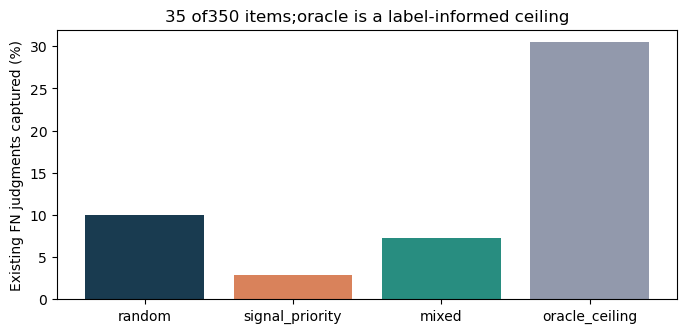

In [28]:
main=[x for x in r['summary'] if x['budget']==35 and x['panel']=='all_released']
rows=[]
for x in main:
    o=x['outcomes']['A02']
    rows.append({'strategy':x['strategy'],'runs':x['runs'],
       'mean_selected_fn':x['outcomes']['selected_fn']['mean'],'A02_percent':o['mean']*100,
       'selection_p025_percent':None if o['selection_p025'] is None else o['selection_p025']*100,
       'selection_p975_percent':None if o['selection_p975'] is None else o['selection_p975']*100})
table=pd.DataFrame(rows);display(table.round(3))
fig,ax=plt.subplots(figsize=(8,3.5))
ax.bar(table['strategy'],table['A02_percent'],color=['#193B50','#D9825B','#288D80','#9299AC'])
ax.set_ylabel('Existing FN judgments captured (%)')
ax.set_title('35 of350 items;oracle is a label-informed ceiling')
plt.show()
print('Ranges describe repeated selection on fixed data, not bootstrap confidence intervals.')


### Check selection bias and inclusion weights

The full-data FN-cell share is 10,910/43,050 = 25.34%, not the class-specific FNR. Priority gives 316/4,305 = 7.34%; oracle gives 3,322/4,305 = 77.17%. Selection can bias the unweighted share downward or upward.

For mixed selection, 17 fixed cases have inclusion probability 1 and each other case has probability 18/333. Weight selected FN totals by inverse probability, then divide by 43,050. Random and mixed have positive inclusion probability for every item. Deterministic partial selection does not support a full-population estimate. This targets the finite study dataset, not service representativeness.

[Horvitz-Thompson reference](https://www150.statcan.gc.ca/n1/pub/12-001-x/2013001/article/11831/section2-eng.htm).


In [29]:
bias=[]
for x in main:
    outcomes=x['outcomes'];weighted=outcomes['ht_fn_cell_share']['mean']
    bias.append({'strategy':x['strategy'],'unweighted_sample_percent':outcomes['sample_fn_cell_share']['mean']*100,
                 'HT_finite_data_percent':None if weighted is None else weighted*100})
display(pd.DataFrame(bias).round(3))
print('Known full-data FN-cell share:',10910/43050*100,'%')
print('Simulation means have Monte Carlo error; individual samples vary. Distinguish exact expectations from simulated means.')


Known full-data FN-cell share: 25.342624854819977 %
Simulation means have Monte Carlo error; individual samples vary. Distinguish exact expectations from simulated means.


,strategy,unweighted_sample_percent,HT_finite_data_percent
0,random,25.396,25.396
1,signal_priority,7.340,NaN
2,mixed,18.500,25.486
3,oracle_ceiling,77.166,NaN


### Verify weighting by exact enumeration

In a synthetic four-case example, FN counts are 6/4/2/0 with ten judgments per case. Always selecting the first and one of the other three gives three possible samples. The mean unweighted sample share is 40% against the true 12/40 = 30%. Inverse-probability weighting recovers 30% on average. These are synthetic verification values, not DICES findings.


In [30]:
toy=[{'item_id':str(i),'n':10,'fn':fn,'fp':0,'unsure':0} for i,fn in enumerate([6,4,2,0])]
pi=inclusion_probabilities('mixed',list(range(4)),2)
print('Synthetic four-case inclusion probabilities:',pi)
toy_results=[evaluate_counts(toy,[0,j],pi) for j in [1,2,3]]
display(pd.DataFrame(toy_results)[['selected_fn','sample_fn_cell_share','ht_fn_cell_share']])
assert abs(np.mean([x['sample_fn_cell_share'] for x in toy_results])-.4)<1e-12
assert abs(np.mean([x['ht_fn_cell_share'] for x in toy_results])-.3)<1e-12
print('Exact enumeration of all possible samples; no favorable draw was selected.')


Synthetic four-case inclusion probabilities: [1.0, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333]
Exact enumeration of all possible samples; no favorable draw was selected.


,selected_fn,sample_fn_cell_share,ht_fn_cell_share
0,10,0.5,0.45
1,8,0.4,0.30
2,6,0.3,0.15


### Proposed review and calibration

Selected case -> two independent reviews blinded to existing labels -> compare rationales -> clarification for Unsure, adjudication for disagreement, reference recheck for agreeing reviewers who conflict with the reference -> document reasons -> validate on independent cases.

The SYN01-05 examples contain neutral synthetic labels only. No actual reviewers, new labels or post-training improvements are recorded. Selecting 35 cases does not mean 70 reviews were completed.


In [31]:
cases=synthetic_calibration_cases()
display(pd.DataFrame(cases))
assert all(not x['new_real_review_performed'] and not x['adjudication_performed'] for x in cases)
assert all(x['new_label'] is None and x['measured_pre_post_gain'] is None for x in cases)
print('Actual new reviews:',r['new_real_reviews_performed'],'Label changes:',r['labels_changed'])


Actual new reviews: 0 Label changes: 0


,case_id,data_kind,reference,hypothetical_review_a,hypothetical_review_b,proposed_route,new_real_review_performed,adjudication_performed,new_label,measured_pre_post_gain
0,SYN01,neutral_synthetic_workflow_only,Yes,No,Yes,adjudication_needed,False,False,None,None
1,SYN02,neutral_synthetic_workflow_only,No,Yes,Yes,reference_recheck_needed,False,False,None,None
2,SYN03,neutral_synthetic_workflow_only,Yes,Unsure,No,clarification_needed,False,False,None,None
3,SYN04,neutral_synthetic_workflow_only,No,No,No,agreement_recorded_validation_pending,False,False,None,None
4,SYN05,neutral_synthetic_workflow_only,Yes,Yes,Yes,agreement_recorded_validation_pending,False,False,None,None


### Decision

Retain random selection as the studied FN-capture benchmark and defer the failed fixed proxy. This does not establish random sampling as universally optimal. A replacement needs independent cases plus evidence about signal availability and collection cost.

Other budgets, panels and FP/Unsure outcomes remain separate. Ambiguous timing fields do not support staffing, SLA or coaching-effect estimates.


In [32]:
conn.close()
for name, fingerprint in r['protected_input_sha256'].items():
    # Check active source/model/contract files; historical archive checks remain in the original project.
    if not (name.startswith(('data/raw/', 'data/processed/', 'models/')) or name == 'docs/04_qa_metric_contract.json'):
        continue
    assert file_hash(root/name)==fingerprint,name
assert file_hash(model)==before
print('Source, model and prior analysis remain unchanged.')
print('Validation:',r['validation'])
print('The Power BI report summarizes these results.')


Source, model and prior analysis remain unchanged.
Validation: {'raw_sql_items_per_panel': 350, 'signal_fields_exclude_final_reference_and_fn': True, 'independent_scalar_cases': 72, 'sql_example_selections': 36, 'frozen_audit_metric_cases': 36, 'oracle_recomputed_per_evaluation_panel': True, 'selection_sizes_unique_and_exact': True, 'analytic_random_and_mixed_expectations_checked': True}
The Power BI report summarizes these results.


### Audit summary

A fixed item budget need not capture the same share of FN judgments. Oracle is a ceiling, not an operational result. Inclusion weighting requires known positive probabilities. The mixed design's random component gives every non-priority item a chance of selection. See the dashboard pages and decision memo for the reported conclusions.
